# Fundamentals of Machine Learning — Exercise 6

## Decision Trees, Random Forests, and Extra Trees

A linear model uses one weighted equation. A decision tree builds a prediction through a sequence of questions such as:

> Is feature 2 less than 1.7?

This exercise moves from one manually verified split to complete trees and ensembles.

The working rhythm remains:

> **question → prediction → computation → visualisation → interpretation → verification**

### Learning outcomes

After completing this exercise, you should be able to:

- explain class impurity and the purpose of a split,
- calculate the weighted Gini impurity of one candidate split,
- distinguish impurity before and after a split,
- explain how tree depth affects bias and variance,
- identify overfitting from training and test behaviour,
- compare a decision tree, Random Forest, and Extra Trees,
- explain bootstrap sampling and random feature subsets,
- use out-of-bag evaluation appropriately,
- interpret feature importance cautiously,
- use AI to challenge an overconfident model interpretation.

**Recommended duration:** 110–120 minutes.

## How to work in this exercise

Most code is prepared. You will:

1. calculate one small example manually,
2. predict how a modelling choice changes the result,
3. compare training and test evidence,
4. inspect both performance and model behaviour,
5. state at least one limitation of every interpretation.

## 0. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, make_moons
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

sns.set_theme(style='whitegrid', context='notebook')
RANDOM_STATE = 42


## Reading: How Decision Trees Work

A **Decision Tree** is a supervised machine learning algorithm used for classification and regression. It makes predictions by repeatedly dividing the dataset into smaller groups based on conditions applied to individual features.

A decision tree consists of three types of components:

- **Root node:** The first node, containing all training samples.
- **Internal nodes:** Nodes that test a condition on a feature and divide samples into smaller groups.
- **Leaf nodes:** Terminal nodes that produce the final prediction.

#### How does a decision tree classify a sample?

Consider a model that predicts whether a tumor is benign or malignant based on measured characteristics.

A simplified decision tree might use the following rules:

1. Is the mean radius smaller than 15?
2. If yes, is the mean texture smaller than 20?
3. Based on the answers, assign the sample to a leaf node.

Each sample follows exactly one path from the root to a leaf.

The predicted class is determined by the most frequent class among the training samples that reached that leaf.

For example, if a leaf contains:

- 15 benign samples,
- 5 malignant samples,

the model predicts **benign**.

It can also estimate class probabilities from the class proportions in the leaf:

$$
P(\text{benign}) = \frac{15}{20} = 0.75
$$

$$
P(\text{malignant}) = \frac{5}{20} = 0.25
$$

These probabilities can be obtained using the `predict_proba()` method.

#### How is a decision tree constructed?

The tree is built recursively, starting with all training samples in the root node.

At each node, the algorithm:

1. Considers candidate features.
2. Evaluates possible thresholds for each feature.
3. Selects the feature and threshold that best separate the classes.
4. Divides the samples into two child nodes.
5. Repeats the process until a stopping condition is reached.

For example, a node may use the condition:

`mean radius <= 15.0`

Samples satisfying the condition go to the left child, while the remaining samples go to the right child.

But how does the algorithm determine which split is the best?

It uses a measure of **node impurity**, such as Gini impurity.

The goal is to create child nodes that contain samples belonging predominantly to a single class.

We will examine Gini impurity and the selection of the best split in the next section.

#### Controlling tree complexity

A decision tree can continue splitting until its leaves contain very few samples. However, a very deep tree may learn patterns specific to the training data rather than general relationships.

This is called **overfitting**.

We can control the complexity of a tree using parameters such as:

- `max_depth`: Maximum depth of the tree.
- `min_samples_split`: Minimum number of samples required to split an internal node.
- `min_samples_leaf`: Minimum number of samples allowed in a leaf.

A shallow tree may be too simple to capture important patterns (**underfitting**), while a very deep tree may become overly sensitive to the training data (**overfitting**).

The objective is to find a tree that performs well on previously unseen data.


## 1. What does impurity measure?

A node is pure when all observations have the same class.

For class proportions `p₁, …, pₖ`, Gini impurity is

$$
Gini = 1 - \sum_j p_j^2.
$$

For two classes:

- impurity is `0` for a pure node,
- impurity is highest at a 50/50 mixture.

In [7]:
def gini_from_labels(labels):
    labels = np.asarray(labels)
    proportions = pd.Series(labels).value_counts(normalize=True)
    return 1 - np.sum(proportions ** 2)


examples = {
    'pure [0,0,0,0]': [0, 0, 0, 0],
    'mixed [0,0,1,1]': [0, 0, 1, 1],
    'uneven [0,0,0,1]': [0, 0, 0, 1],
}

pd.Series({name: gini_from_labels(values) for name, values in examples.items()}).round(3)

pure [0,0,0,0]      0.000
mixed [0,0,1,1]     0.500
uneven [0,0,0,1]    0.375
dtype: float64

### Stop and explain

1. Why does the 50/50 node have higher impurity than the 75/25 node?

## 2. Manual first split on a tiny dataset

Suppose we want to predict whether a student passes (`1`) from weekly study hours.

In [8]:
tiny = pd.DataFrame({
    'hours': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'passed': [0, 0, 0, 0, 1, 0, 1, 1, 1, 1],
})

tiny

,hours,passed
0,1,0
1,2,0
2,3,0
3,4,0
4,5,1
5,6,0
6,7,1
7,8,1
8,9,1
9,10,1


We test the split:

> `hours <= 4.5`

### Activity 1 - Calculate before running

1. Write the labels in the left node(part).
2. Write the labels in the right node(part).
3. Calculate each node's Gini impurity.
4. Calculate the weighted post-split impurity:

$$
G_{split}=\frac{n_L}{n}G_L+\frac{n_R}{n}G_R.
$$

5. Compare it with the impurity before splitting.

In [5]:
def evaluate_numeric_split(frame, feature, target, threshold):
    left = frame.loc[frame[feature] <= threshold, target]
    right = frame.loc[frame[feature] > threshold, target]

    gini_parent = gini_from_labels(frame[target])
    gini_left = gini_from_labels(left)
    gini_right = gini_from_labels(right)

    weighted_gini = (
        len(left) / len(frame) * gini_left
        + len(right) / len(frame) * gini_right
    )

    return pd.Series({
        'parent gini': gini_parent,
        'left size': len(left),
        'left gini': gini_left,
        'right size': len(right),
        'right gini': gini_right,
        'weighted post-split gini': weighted_gini,
        'impurity decrease': gini_parent - weighted_gini,
    })


evaluate_numeric_split(tiny, 'hours', 'passed', threshold=4.5).round(3)

parent gini                 0.500
left size                   4.000
left gini                   0.000
right size                  6.000
right gini                  0.278
weighted post-split gini    0.167
impurity decrease           0.333
dtype: float64

### Compare all possible boundaries

Candidate thresholds lie halfway between consecutive observed values.

In [6]:
candidate_thresholds = (
    tiny['hours'].sort_values().to_numpy()[:-1]
    + tiny['hours'].sort_values().to_numpy()[1:]
) / 2

split_results = []

for threshold in candidate_thresholds:
    result = evaluate_numeric_split(
        tiny,
        'hours',
        'passed',
        threshold,
    )
    result['threshold'] = threshold
    split_results.append(result)

split_table = pd.DataFrame(split_results).sort_values(
    'weighted post-split gini'
)

split_table[['threshold', 'weighted post-split gini', 'impurity decrease']].round(3)

,threshold,weighted post-split gini,impurity decrease
3,4.5,0.167,0.333
5,6.5,0.167,0.333
6,7.5,0.286,0.214
2,3.5,0.286,0.214
4,5.5,0.320,0.180
1,2.5,0.375,0.125
7,8.5,0.375,0.125
0,1.5,0.444,0.056
8,9.5,0.444,0.056


### Activity 2 - Interpret the best split

1. Which threshold is preferred?
2. Is the result perfectly pure?
3. Which observation prevents perfect separation?

## 3. A decision tree creates axis-aligned regions

We use noisy two-moon data to visualise how depth changes the decision boundary.

Predict first:

| Maximum depth | Expected training fit | Expected boundary complexity | Overfitting risk |
|---:|---|---|---|
| 1 |  |  |  |
| 3 |  |  |  |
| None |  |  |  |

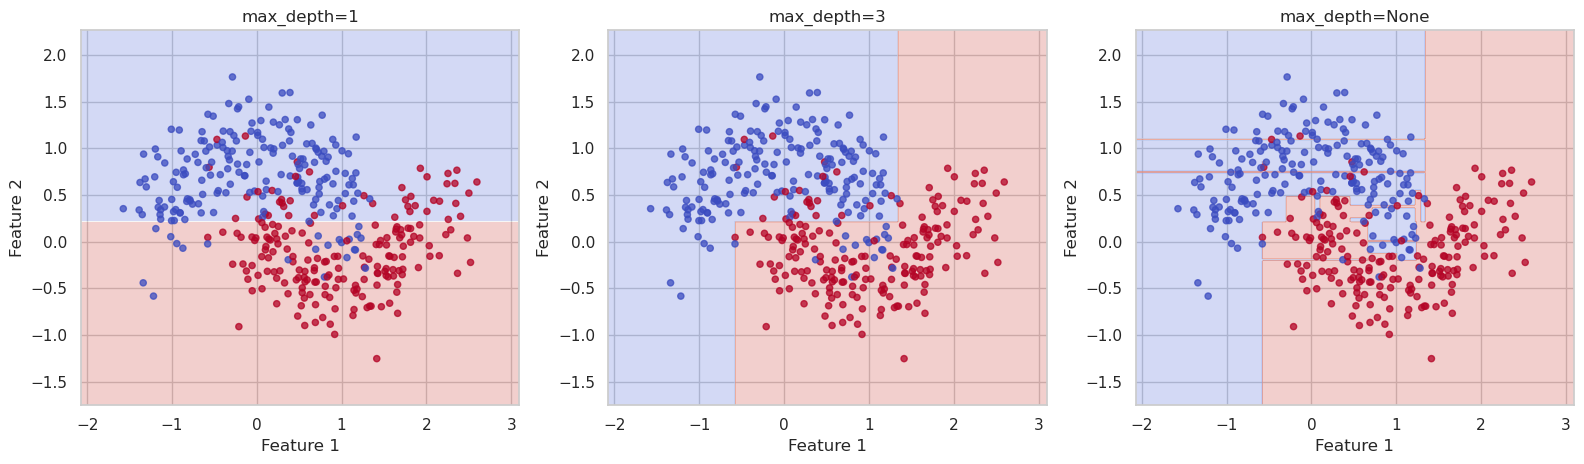

,max_depth,leaves,train accuracy,test accuracy
0,1,2,0.831,0.810
1,3,6,0.905,0.895
2,None,43,1.000,0.886


In [9]:
X_moons, y_moons = make_moons(
    n_samples=600,
    noise=0.28,
    random_state=RANDOM_STATE,
)

X_train_moons, X_test_moons, y_train_moons, y_test_moons = train_test_split(
    X_moons,
    y_moons,
    test_size=0.35,
    stratify=y_moons,
    random_state=RANDOM_STATE,
)


def plot_decision_regions(model, X, y, axis, title):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300),
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    prediction = model.predict(grid).reshape(xx.shape)

    axis.contourf(xx, yy, prediction, alpha=0.25, cmap='coolwarm')
    axis.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', s=20, alpha=0.75)
    axis.set_title(title)
    axis.set_xlabel('Feature 1')
    axis.set_ylabel('Feature 2')


depths = [1, 3, None]
tree_depth_results = []

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

for axis, depth in zip(axes, depths):
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=RANDOM_STATE,
    )
    model.fit(X_train_moons, y_train_moons)

    train_prediction = model.predict(X_train_moons)
    test_prediction = model.predict(X_test_moons)

    tree_depth_results.append({
        'max_depth': str(depth),
        'leaves': model.get_n_leaves(),
        'train accuracy': accuracy_score(y_train_moons, train_prediction),
        'test accuracy': accuracy_score(y_test_moons, test_prediction),
    })

    plot_decision_regions(
        model,
        X_train_moons,
        y_train_moons,
        axis,
        title=f'max_depth={depth}',
    )

plt.tight_layout()
plt.show()

pd.DataFrame(tree_depth_results).round(3)

### Activity 3 - Diagnose underfitting and overfitting

For each tree, use both the boundary and the train/test metrics.

Then complete:

> The depth-1 tree underfits because __________.
>
> The unrestricted tree overfits because __________.
>
> A small training error alone is not sufficient because __________.


## Reading (5 min): ROC curve and AUC

A binary classifier often produces a probability estimate rather than only a class label.

For example, a model may predict that a sample belongs to the positive class with probability 0.75.

By default, we typically use a **decision threshold of 0.5**:

- Probability $\geq 0.5$: predict class 1.
- Probability $< 0.5$: predict class 0.

But what happens if we change this threshold?

A lower threshold usually identifies more positive samples, but also increases the number of false positives. A higher threshold generally does the opposite.

#### True Positive Rate and False Positive Rate

The ROC curve uses two quantities:

**True Positive Rate (TPR)**, also called recall or sensitivity:

$$
TPR = \frac{TP}{TP+FN}
$$

**False Positive Rate (FPR)**:

$$
FPR = \frac{FP}{FP+TN}
$$

TPR measures how many actual positive samples are correctly identified.

FPR measures how many actual negative samples are incorrectly classified as positive.

#### The ROC curve

The **Receiver Operating Characteristic (ROC)** curve shows the relationship between TPR and FPR for different decision thresholds.

- Horizontal axis: False Positive Rate (FPR).
- Vertical axis: True Positive Rate (TPR).
- Each point corresponds to a decision threshold.
- The ideal classifier reaches the top-left corner: FPR = 0, TPR = 1.

#### Area Under the Curve (AUC)

**AUC** summarizes the ROC curve into a single number.

- **AUC = 1.0:** Perfect discrimination.
- **AUC = 0.5:** No discrimination, equivalent to random ranking.
- **AUC < 0.5:** Predictions tend to rank the classes in the opposite direction.

AUC can also be interpreted as the probability that a randomly selected positive sample receives a higher score than a randomly selected negative sample, with ties counted as half.

Unlike accuracy, ROC AUC evaluates the model across all decision thresholds rather than at one fixed threshold.

**Important:** A high ROC AUC does not guarantee good performance at the threshold used in practice. For highly imbalanced datasets, a Precision-Recall curve can be more informative.


## 4. Real classification data: breast-cancer diagnosis measurements

The built-in dataset contains numerical measurements derived from digitised cell-nucleus images.

The target has two classes. We keep the original target encoding and evaluate with stratified train/test data.

In [2]:
cancer = load_breast_cancer(as_frame=True)
X_cancer = cancer.data.copy()
y_cancer = cancer.target.copy()

print('Rows, features:', X_cancer.shape)
display(y_cancer.value_counts().rename(index=dict(enumerate(cancer.target_names))))

Rows, features: (569, 30)


target
benign       357
malignant    212
Name: count, dtype: int64

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X_cancer,
    y_cancer,
    test_size=0.30,
    stratify=y_cancer,
    random_state=RANDOM_STATE,
)

### Predict before fitting

Which model is more likely to have the larger train–test gap?

- a depth-3 tree,
- an unrestricted tree.

Explain before running.

In [4]:
real_tree_models = {
    'Decision tree - depth 3': DecisionTreeClassifier(
        max_depth=3,
        min_samples_leaf=5,
        random_state=RANDOM_STATE,
    ),
    'Decision tree - unrestricted': DecisionTreeClassifier(
        random_state=RANDOM_STATE,
    ),
}

real_tree_rows = []

for name, model in real_tree_models.items():
    model.fit(X_train, y_train)

    train_probability = model.predict_proba(X_train)[:, 1]
    test_probability = model.predict_proba(X_test)[:, 1]
    train_prediction = model.predict(X_train)
    test_prediction = model.predict(X_test)

    real_tree_rows.append({
        'model': name,
        'leaves': model.get_n_leaves(),
        'train accuracy': accuracy_score(y_train, train_prediction),
        'test accuracy': accuracy_score(y_test, test_prediction),
        'test F1': f1_score(y_test, test_prediction),
        'test ROC-AUC': roc_auc_score(y_test, test_probability),
    })

real_tree_results = pd.DataFrame(real_tree_rows)
real_tree_results.round(3)

,model,leaves,train accuracy,test accuracy,test F1,test ROC-AUC
0,Decision tree - depth 3,7,0.972,0.936,0.949,0.946
1,Decision tree - unrestricted,16,1.000,0.918,0.935,0.913


### Activity 4 - Select the defensible single tree

1. Which tree would you report?
2. What evidence supports the choice?
3. What information is lost when a tree is constrained?
4. What is gained?

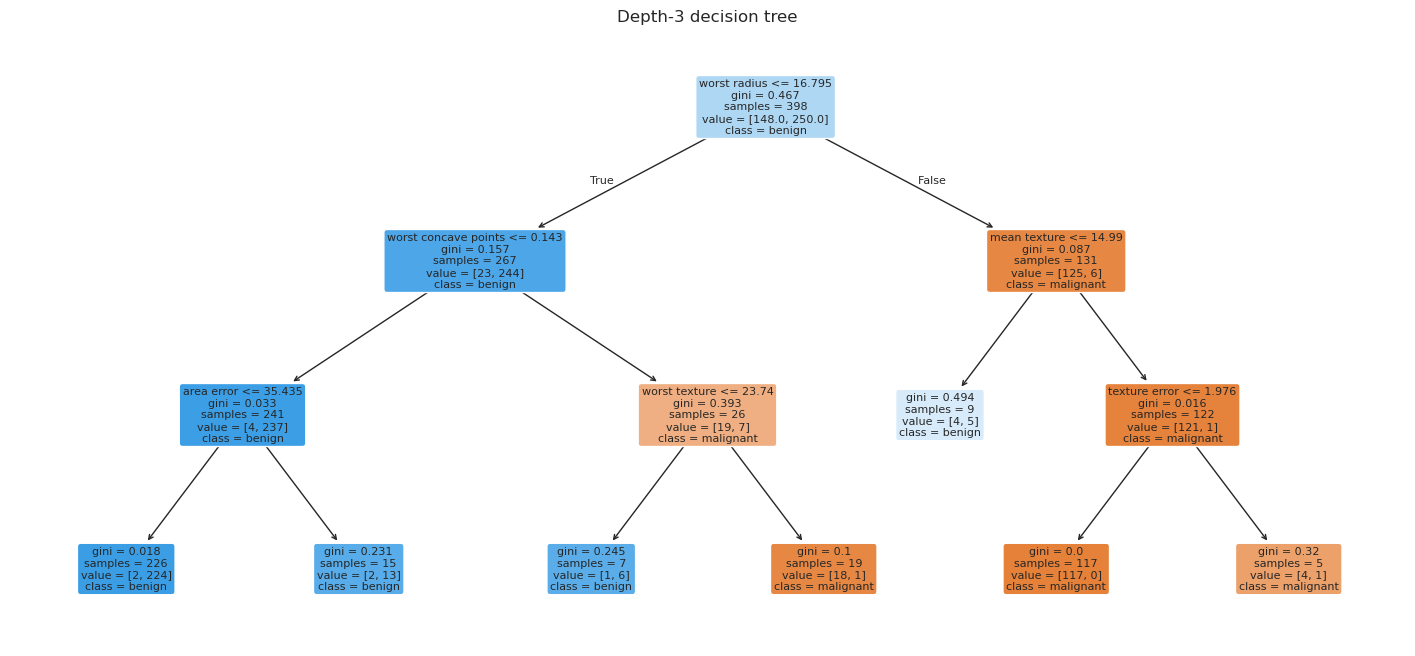

In [5]:
selected_tree = real_tree_models['Decision tree - depth 3']

plt.figure(figsize=(18, 8))
plot_tree(
    selected_tree,
    feature_names=X_cancer.columns,
    class_names=cancer.target_names,
    filled=True,
    rounded=True,
    fontsize=8,
)
plt.title('Depth-3 decision tree')
plt.show()

### Read one path

Choose one leaf and describe the sequence of conditions leading to it.

Do not say that the path causes the diagnosis. It is a predictive rule learned from this dataset.

## 5. Why combine many trees?

A single deep tree is unstable: small data changes can produce a different structure.

### Random Forest

- trains trees on bootstrap samples,
- considers a random subset of features at each split,
- averages probabilities or votes,
- can estimate out-of-bag performance from observations omitted from each bootstrap sample.

### Extra Trees

- uses random feature subsets,
- also introduces more randomness into candidate split thresholds,
- usually uses the whole training sample by default rather than bootstrap sampling.

The added randomness aims to reduce correlation between trees.

### Predict before fitting

Compared with one unrestricted tree, what do you expect for:

- training accuracy,
- test performance,
- stability,
- interpretability?

In [ ]:
ensemble_models = {
    'Decision tree — unrestricted': DecisionTreeClassifier(
        random_state=RANDOM_STATE,
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=160,
        max_features='sqrt',
        oob_score=True,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
    'Extra Trees': ExtraTreesClassifier(
        n_estimators=160,
        max_features='sqrt',
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
}

ensemble_rows = []

for name, model in ensemble_models.items():
    model.fit(X_train, y_train)

    train_prediction = model.predict(X_train)
    test_prediction = model.predict(X_test)
    test_probability = model.predict_proba(X_test)[:, 1]

    row = {
        'model': name,
        'train accuracy': accuracy_score(y_train, train_prediction),
        'test accuracy': accuracy_score(y_test, test_prediction),
        'test F1': f1_score(y_test, test_prediction),
        'test ROC-AUC': roc_auc_score(y_test, test_probability),
        'OOB accuracy': getattr(model, 'oob_score_', np.nan),
    }
    ensemble_rows.append(row)

ensemble_results = pd.DataFrame(ensemble_rows)
ensemble_results.round(3)

### Activity 5 - Explain variance reduction

1. Did ensembles improve test performance over the unrestricted tree?
2. Why can averaging many individually overfitted trees improve generalisation?
3. Why should trees be decorrelated rather than identical?
4. Why is the OOB estimate not available for the default Extra Trees model here?

### Confusion matrices for the two ensembles

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for axis, name in zip(axes, ['Random Forest', 'Extra Trees']):
    model = ensemble_models[name]
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        model.predict(X_test),
        display_labels=cancer.target_names,
        ax=axis,
        colorbar=False,
    )
    axis.set_title(name)

plt.tight_layout()
plt.show()

## 6. Feature importance is evidence about a fitted model, not causality

We compare:

- impurity-based importance from Random Forest,
- permutation importance measured on the test set.

Permutation importance asks how much performance decreases after one feature is shuffled.

In [ ]:
random_forest = ensemble_models['Random Forest']

impurity_importance = pd.Series(
    random_forest.feature_importances_,
    index=X_cancer.columns,
    name='impurity importance',
)

permutation = permutation_importance(
    random_forest,
    X_test,
    y_test,
    n_repeats=10,
    scoring='roc_auc',
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

permutation_series = pd.Series(
    permutation.importances_mean,
    index=X_cancer.columns,
    name='permutation importance',
)

importance_comparison = pd.concat(
    [impurity_importance, permutation_series],
    axis=1,
).sort_values('permutation importance', ascending=False)

importance_comparison.head(12).round(4)

In [ ]:
top_features = importance_comparison.head(10).sort_values(
    'permutation importance'
)

top_features.plot.barh(figsize=(9, 5.5))
plt.xlabel('Importance value')
plt.title('Two feature-importance views')
plt.show()

### Activity 6 - Interpret cautiously

1. Do the two importance methods produce exactly the same ranking?
2. Why can correlated features share or substitute importance?
3. Why does high importance not prove that changing the feature would change the diagnosis?
4. State one defensible conclusion from the plot.

# End-of-lab self-check

- [ ] I can calculate Gini impurity for a node.
- [ ] I can calculate weighted impurity after a split.
- [ ] I can explain why a tree selects one threshold over another.
- [ ] I can diagnose underfitting and overfitting from train/test evidence.
- [ ] I can explain bootstrap sampling and random feature subsets.
- [ ] I can explain why averaging decorrelated trees reduces variance.
- [ ] I know when OOB evaluation is available.
- [ ] I can compare a tree, Random Forest, and Extra Trees.
- [ ] I can interpret feature importance without causal claims.

Exercise 7 will examine boosting, where trees are added sequentially to correct earlier errors.